<a href="https://colab.research.google.com/github/fpugong-prog/DASP-B04-FPugong-MySQL/blob/main/Python%20Capstone%20-%20DASP%20-%20B04%20-%20FPugong%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Load all CSV datasets (ensure they are uploaded to your Colab session or working directory)
customers = pd.read_csv("Datasets/customers.csv")
orders = pd.read_csv("Datasets/orders.csv")
order_items = pd.read_csv("Datasets/order_items.csv")
products = pd.read_csv("Datasets/products.csv")
payments = pd.read_csv("Datasets/payments.csv")
shipments = pd.read_csv("Datasets/shipments.csv")
returns = pd.read_csv("Datasets/returns.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [14]:
# Cleaning Order Items: validate quantities and prices
order_items["quantity"] = pd.to_numeric(order_items["quantity"], errors="coerce")
order_items["unit_price_at_purchase"] = (
    order_items["unit_price_at_purchase"]
    .astype(str)
    .str.replace(r"[^\d.]", "", regex=True) # Strips all currency symbols (₱, $) and formatting commas
    .replace("", np.nan)
    .astype(float)
)
order_items = order_items.dropna(
    subset=["order_id", "product_id", "quantity", "unit_price_at_purchase"]
)

# Cleaning Shipments (if required for Option A / B metrics)
shipments["ship_date"] = pd.to_datetime(shipments["ship_date"], errors= "coerce")
shipments["delivered_date"] = pd.to_datetime(
    shipments["delivered_date"], errors="coerce"
)
shipments = shipments.drop_duplicates(subset=["shipment_id"])

# ---------------------------------------------------------
# BUILD MASTER FACT TABLE (Option A Requirement)
# ---------------------------------------------------------
# Ensure orders has order_date parsed from order_datetime
orders["order_date"] = pd.to_datetime(orders["order_datetime"], errors="coerce")
orders = orders.drop_duplicates(subset=["order_id"]).dropna(
    subset=["order_date", "customer_id"]
)

# Merging orders -> order_items -> products -> customers
fact_df = (
    orders.merge(order_items, on="order_id", how="inner")
    .merge(products, on="product_id", how="inner")
    .merge(customers, on="customer_id", how="inner")
)

# Handle orphan records / validate join keys check
print(f"Total rows in Master Fact Table after inner joins: {len(fact_df):,}")

# Calculate line-item total revenue using the correct column
fact_df["line_revenue"] = fact_df["quantity"] * fact_df["unit_price_at_purchase"]

# ---------------------------------------------------------
# COMPUTE CORE KPIS
# ---------------------------------------------------------
total_revenue = fact_df["line_revenue"].sum()
total_orders = fact_df["order_id"].nunique()
total_items_sold = fact_df["quantity"].sum()
aov = total_revenue / total_orders

print("\n--- EXECUTIVE KPI SUMMARY ---")
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Unique Orders: {total_orders:,}")
print(f"Total Items Sold: {total_items_sold:,}")
print(f"Average Order Value (AOV): ${aov:,.2f}")

Total rows in Master Fact Table after inner joins: 27,833

--- EXECUTIVE KPI SUMMARY ---
Total Revenue: $5,450,094.22
Total Unique Orders: 11,478
Total Items Sold: 58,889
Average Order Value (AOV): $474.83


In [16]:
# Merge orders with order_items, products, and customers
fact_df = (
    orders.merge(order_items, on="order_id", how="inner")
    .merge(products, on="product_id", how="inner")
    .merge(customers, on="customer_id", how="inner")
)

# Calculate total line item revenue using the correct column name
fact_df["line_revenue"] = fact_df["quantity"] * fact_df["unit_price_at_purchase"]
print(f"Fact table shape: {fact_df.shape}")

Fact table shape: (27833, 34)


In [18]:
# Merge orders with order_items, products, and customers
fact_df = (
    orders.merge(order_items, on="order_id", how="inner")
    .merge(products, on="product_id", how="inner")
    .merge(customers, on="customer_id", how="inner")
)

# Calculate total line item revenue using the correct column name
fact_df["line_revenue"] = fact_df["quantity"] * fact_df["unit_price_at_purchase"]
print(f"Fact table shape: {fact_df.shape}")

Fact table shape: (27833, 34)


In [19]:
total_revenue = fact_df["line_revenue"].sum()
total_orders = fact_df["order_id"].nunique()
aov = total_revenue / total_orders

print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value (AOV): ${aov:,.2f}")

Total Revenue: $5,450,094.22
Total Orders: 11,478
Average Order Value (AOV): $474.83


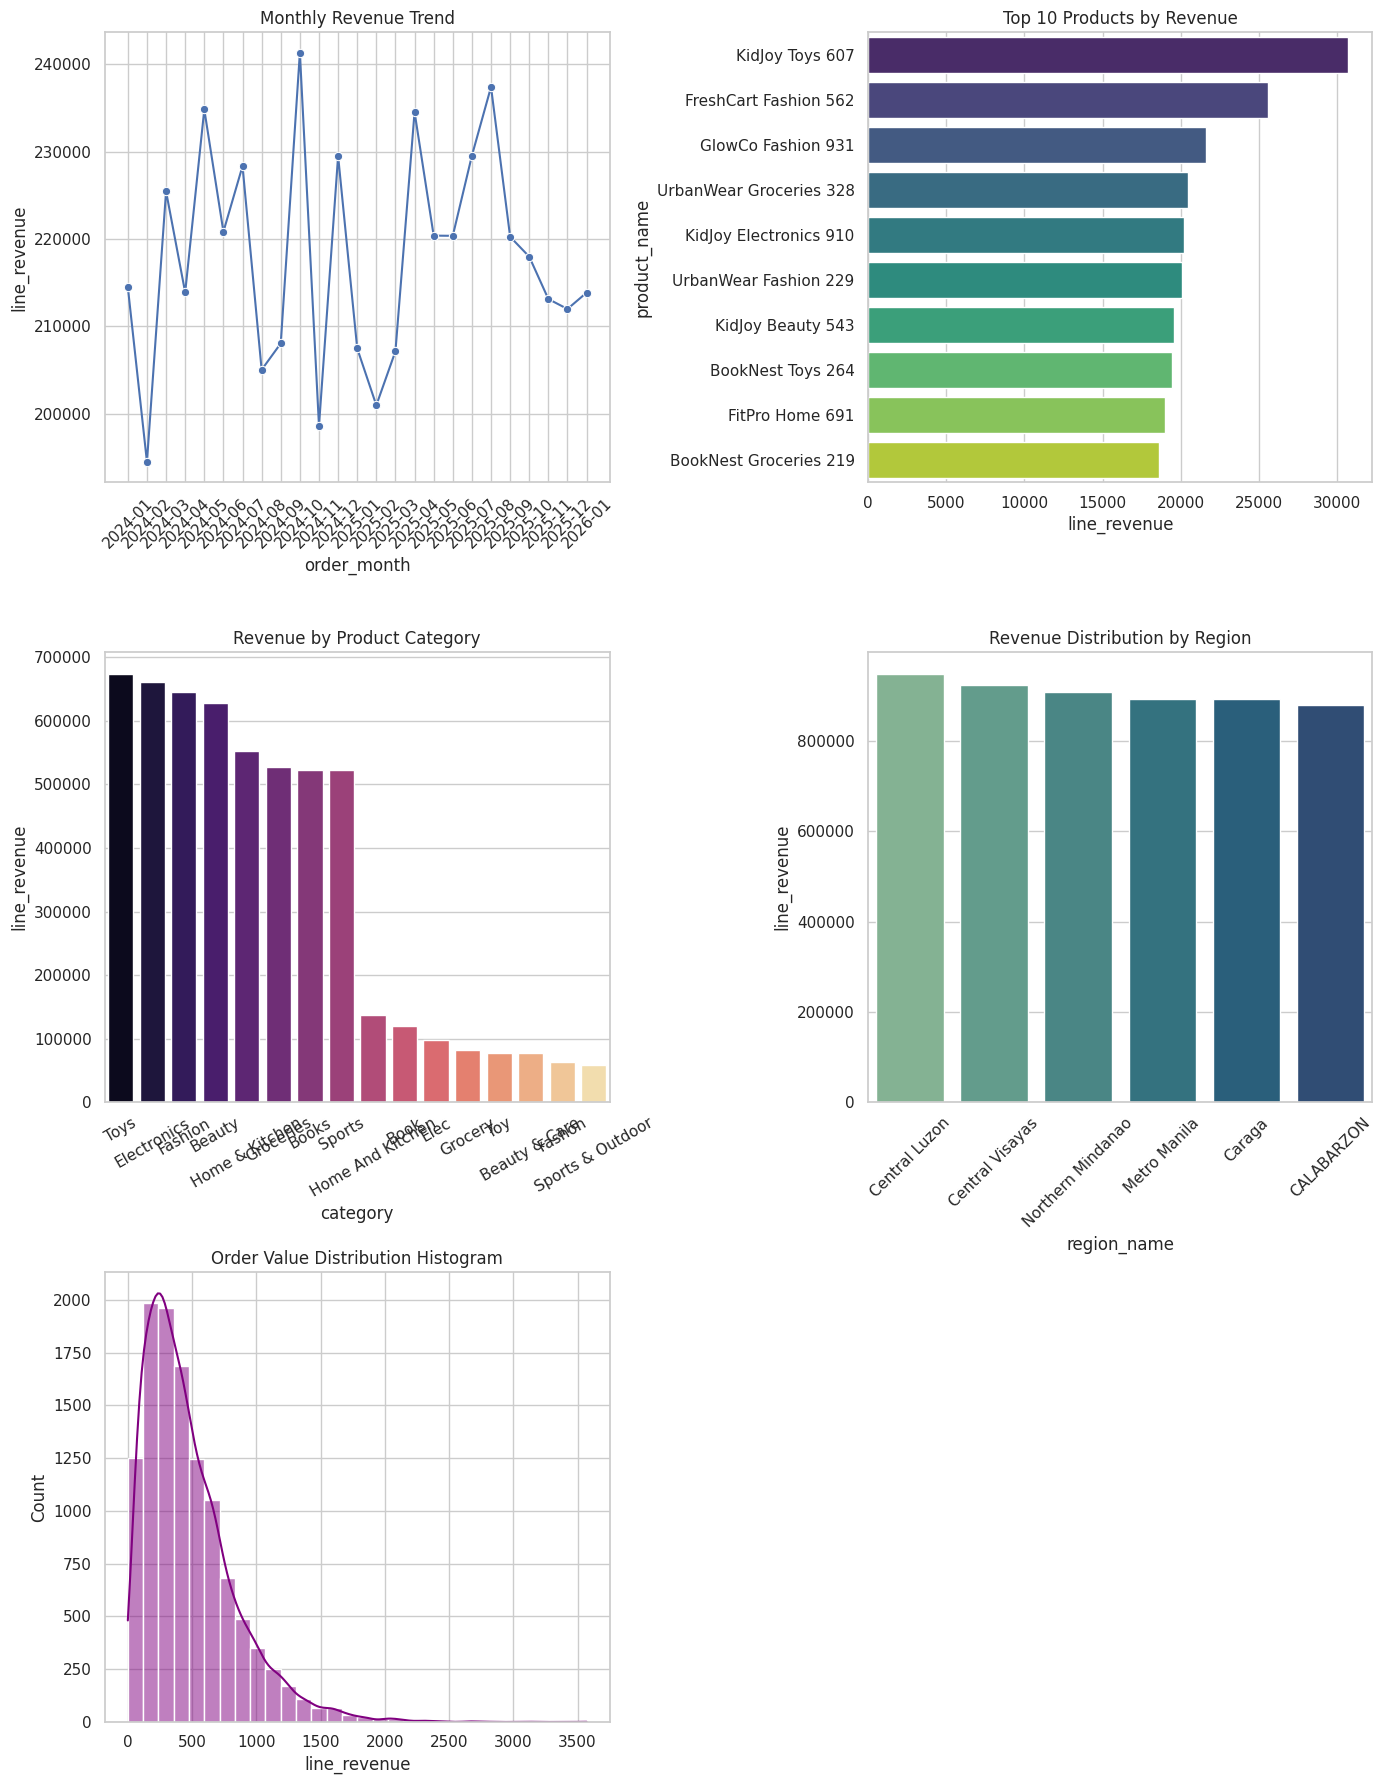

In [21]:
# Set general style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(14, 18))

# Chart 1: Monthly Revenue Trend
fact_df["order_month"] = fact_df["order_date"].dt.to_period("M")
monthly_rev = (
    fact_df.groupby("order_month")["line_revenue"].sum().reset_index()
)
monthly_rev["order_month"] = monthly_rev["order_month"].astype(str)
sns.lineplot(
    data=monthly_rev,
    x="order_month",
    y="line_revenue",
    marker="o",
    ax=axes[0, 0],
    color="b",
)
axes[0, 0].set_title("Monthly Revenue Trend")
axes[0, 0].tick_params(axis="x", rotation=45)

# Chart 2: Top 10 Products by Revenue
top_products = (
    fact_df.groupby("product_name")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
    .head(10)
)
sns.barplot(
    data=top_products,
    x="line_revenue",
    y="product_name",
    ax=axes[0, 1],
    palette="viridis",
    hue="product_name",
    legend=False
)
axes[0, 1].set_title("Top 10 Products by Revenue")

# Chart 3: Revenue by Category
cat_rev = (
    fact_df.groupby("category")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
)
sns.barplot(
    data=cat_rev,
    x="category",
    y="line_revenue",
    ax=axes[1, 0],
    palette="magma",
    hue="category",
    legend=False
)
axes[1, 0].set_title("Revenue by Product Category")
axes[1, 0].tick_params(axis="x", rotation=30)

# Chart 4: Revenue by Region
region_rev = (
    fact_df.groupby("region_name")["line_revenue"]
    .sum()
    .reset_index()
    .sort_values(by="line_revenue", ascending=False)
)
sns.barplot(
    data=region_rev,
    x="region_name",
    y="line_revenue",
    ax=axes[1, 1],
    palette="crest",
    hue="region_name",
    legend=False
)
axes[1, 1].set_title("Revenue Distribution by Region")
axes[1, 1].tick_params(axis="x", rotation=45)

# Chart 5: AOV / Customer Spend Distribution Histogram
order_totals = (
    fact_df.groupby("order_id")["line_revenue"].sum().reset_index()
)
sns.histplot(
    order_totals["line_revenue"],
    bins=30,
    kde=True,
    ax=axes[2, 0],
    color="purple",
)
axes[2, 0].set_title("Order Value Distribution Histogram")

# Hide unused subplot slot
axes[2, 1].axis("off")

plt.tight_layout()
plt.savefig("dashboard_charts_overview.png", dpi=300)
plt.show()